# Step #1 Load the Data

In [1]:
# Time Series Forecasting - Multivariate Time Series Models for Stock Market Prediction
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, TensorFlow 2.21, Keras 3.15, pandas 3.0, and yfinance 1.5

import keras
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import yfinance as yf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import RobustScaler

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})
keras.utils.set_random_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(tf.config.list_physical_devices('GPU'))}")

start_date = "2010-01-01"
end_date = "2026-01-01"
stock_name = "NASDAQ Composite"
symbol = "^IXIC"

df = yf.download(
    symbol,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    multi_level_index=False,
    progress=False,
)
if df.empty:
    raise RuntimeError("yfinance returned no data for the NASDAQ Composite")

print(df.shape)
df.head()

TensorFlow version: 2.21.0


Available GPUs: 0


(4024, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,2308.419922,2311.149902,2294.409912,2294.409912,1931380000
2010-01-05,2308.709961,2313.729980,2295.620117,2307.270020,2367860000
2010-01-06,2301.090088,2314.070068,2295.679932,2307.709961,2253340000
2010-01-07,2300.050049,2301.300049,2285.219971,2298.090088,2270050000
2010-01-08,2317.169922,2317.600098,2290.610107,2292.239990,2145390000


# Step #2 Exploring the Data

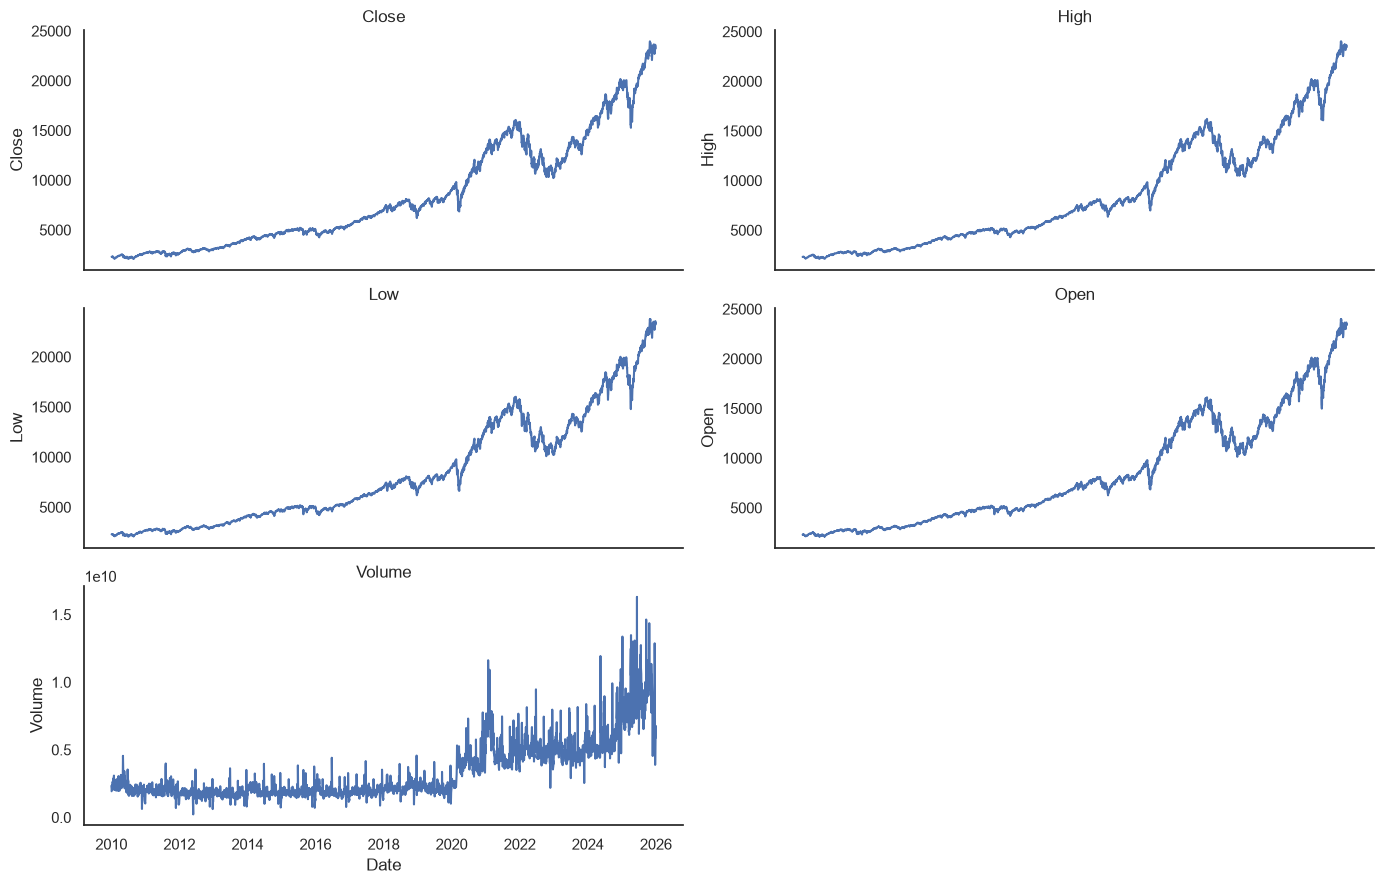

In [2]:
df_plot = df.copy()
_, axes = plt.subplots(nrows=3, ncols=2, sharex=True, figsize=(14, 9))

for ax, column in zip(axes.flat, df_plot.columns):
    sns.lineplot(x=df_plot.index, y=df_plot[column], ax=ax)
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.set_title(column)

for ax in axes.flat[len(df_plot.columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

# Step #3 Preprocessing and Feature Selection

In [3]:
market = df.sort_index().dropna().copy()

price_columns = ["Open", "High", "Low", "Close"]
price_log_returns = np.log(market[price_columns]).diff()
volume_log_change = np.log1p(market["Volume"]).diff().rename("Volume")
features = pd.concat([price_log_returns, volume_log_change], axis=1).dropna()

feature_values = features.to_numpy()
close_returns = features[["Close"]].to_numpy()
close_levels = market.loc[features.index, "Close"].to_numpy()
train_size = int(len(features) * 0.8)

print(f"Features: {features.columns.tolist()}")
print(f"Transformed shape: {features.shape}")
print(f"Training rows: {train_size}")
features.tail()

Features: ['Open', 'High', 'Low', 'Close', 'Volume']
Transformed shape: (4023, 5)
Training rows: 3218


,Open,High,Low,Close,Volume
Date,,,,,
2025-12-24,0.006313,0.002469,0.006416,0.002182,-0.660154
2025-12-26,0.003812,0.001837,0.001694,-0.000856,0.285759
2025-12-29,-0.009827,-0.005684,-0.007254,-0.005046,0.233098
2025-12-30,0.002175,-0.000424,0.000740,-0.002357,0.036369
2025-12-31,-0.001912,-0.003227,-0.007590,-0.007591,-0.138271


In [4]:
feature_scaler = RobustScaler()
feature_scaler.fit(feature_values[:train_size])
scaled_features = feature_scaler.transform(feature_values)

target_scaler = RobustScaler()
target_scaler.fit(close_returns[:train_size])
scaled_close_returns = target_scaler.transform(close_returns)

print(f"Scaled feature shape: {scaled_features.shape}")
print(f"Feature scaler center: {np.round(feature_scaler.center_, 6)}")
print(f"Target scaler center: {target_scaler.center_[0]:.6f}")

Scaled feature shape: (4023, 5)
Feature scaler center: [ 0.001444  0.001106  0.00126   0.001003 -0.001445]
Target scaler center: 0.001003


In [5]:
sequence_length = 50


def create_sequences(feature_values, target_values, sequence_length):
    inputs, targets, target_indices = [], [], []
    for target_index in range(sequence_length, len(feature_values)):
        inputs.append(feature_values[target_index - sequence_length:target_index])
        targets.append(target_values[target_index, 0])
        target_indices.append(target_index)

    return (
        np.asarray(inputs, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
        np.asarray(target_indices),
    )


x_all, y_all, target_indices = create_sequences(
    scaled_features,
    scaled_close_returns,
    sequence_length,
)
train_mask = target_indices < train_size
test_mask = target_indices >= train_size

x_train, y_train = x_all[train_mask], y_all[train_mask]
x_test, y_test = x_all[test_mask], y_all[test_mask]
test_target_indices = target_indices[test_mask]

print(f"Training shapes: {x_train.shape}, {y_train.shape}")
print(f"Test shapes: {x_test.shape}, {y_test.shape}")

assert target_indices[train_mask][-1] == train_size - 1
assert test_target_indices[0] == train_size
print(
    "First test target:",
    features.index[test_target_indices[0]].date(),
    "using data through",
    features.index[test_target_indices[0] - 1].date(),
)

Training shapes: (3168, 50, 5), (3168,)
Test shapes: (805, 50, 5), (805,)
First test target: 2022-10-17 using data through 2022-10-14


# Step #4 Model Training

In [6]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(sequence_length, x_train.shape[2])),
        keras.layers.LSTM(32),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1),
    ],
    name="nasdaq_multivariate_lstm",
)
model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.Huber(),
)
model.summary()

Model: "nasdaq_multivariate_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,409 (21.13 KB)

 Trainable params: 5,409 (21.13 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)
history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/20


 1/90 ━━━━━━━━━━━━━━━━━━━━ 3:44 3s/step - loss: 0.2396

 4/90 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.5703

 7/90 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.4305

10/90 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.3950

13/90 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.5264

... (119 outputs left out)

85/90 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.3748

87/90 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.3799

89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.3775

90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.3771 - val_loss: 0.7581


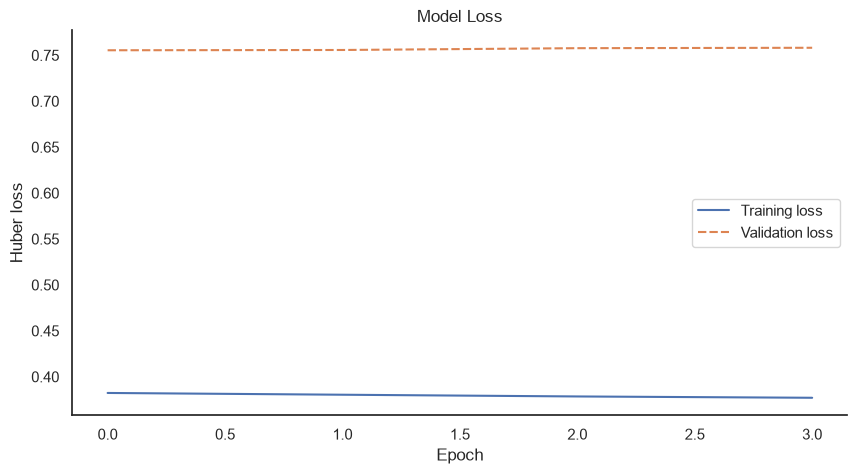

In [8]:
loss_history = pd.DataFrame(
    {
        "Training loss": history.history["loss"],
        "Validation loss": history.history["val_loss"],
    }
)

_, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=loss_history, ax=ax)
ax.set_title("Model Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Huber loss")
plt.show()

# Step #5 Evaluate Model Performance

In [9]:
predicted_returns_scaled = model.predict(x_test, verbose=0)
predicted_returns = target_scaler.inverse_transform(predicted_returns_scaled).ravel()
actual_returns = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

origin_prices = close_levels[test_target_indices - 1]
actual_prices = close_levels[test_target_indices]
predicted_prices = origin_prices * np.exp(predicted_returns)
persistence_prices = origin_prices
training_median_return = float(np.median(close_returns[:train_size]))
drift_prices = origin_prices * np.exp(training_median_return)

model_mae = mean_absolute_error(actual_prices, predicted_prices)
model_rmse = root_mean_squared_error(actual_prices, predicted_prices)
baseline_mae = mean_absolute_error(actual_prices, persistence_prices)
baseline_rmse = root_mean_squared_error(actual_prices, persistence_prices)
drift_mae = mean_absolute_error(actual_prices, drift_prices)
drift_rmse = root_mean_squared_error(actual_prices, drift_prices)
directional_accuracy = np.mean(
    np.sign(predicted_returns) == np.sign(actual_returns)
)
up_day_rate = np.mean(actual_returns > 0)

print(f"LSTM MAE: ${model_mae:,.2f}")
print(f"LSTM RMSE: ${model_rmse:,.2f}")
print(f"Persistence MAE: ${baseline_mae:,.2f}")
print(f"Persistence RMSE: ${baseline_rmse:,.2f}")
print(f"Training-median drift MAE: ${drift_mae:,.2f}")
print(f"Training-median drift RMSE: ${drift_rmse:,.2f}")
print(f"LSTM directional accuracy: {directional_accuracy:.1%}")
print(f"Always-up directional accuracy: {up_day_rate:.1%}")

LSTM MAE: $148.99
LSTM RMSE: $212.89
Persistence MAE: $151.35
Persistence RMSE: $213.73
Training-median drift MAE: $149.77
Training-median drift RMSE: $213.25
LSTM directional accuracy: 56.6%
Always-up directional accuracy: 56.8%


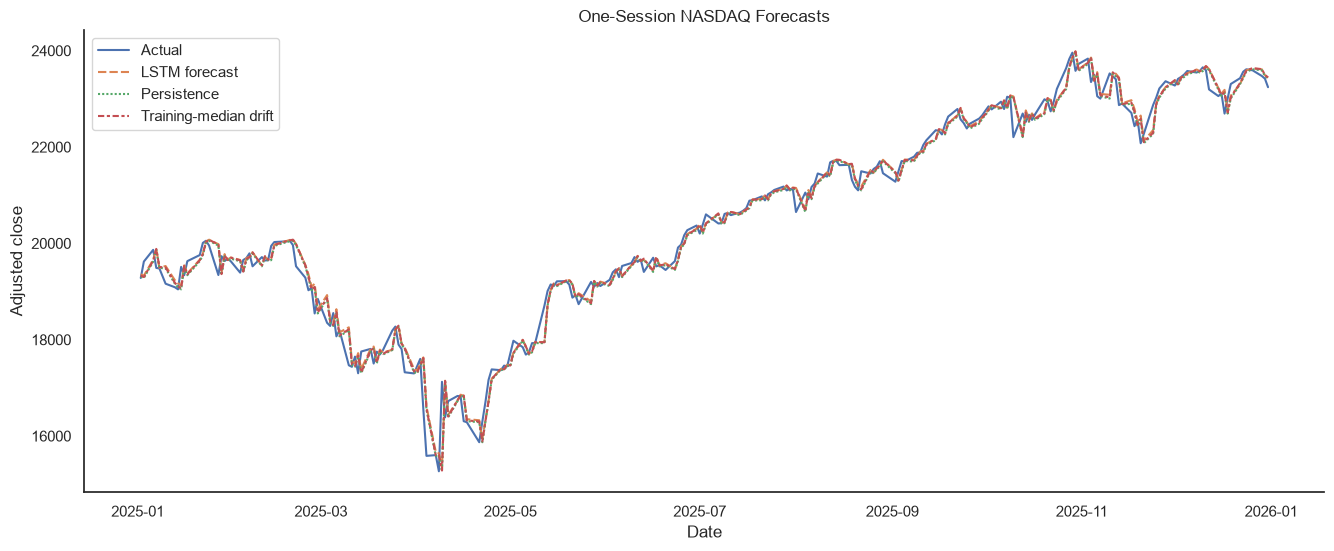

In [10]:
forecast_frame = pd.DataFrame(
    {
        "Actual": actual_prices,
        "LSTM forecast": predicted_prices,
        "Persistence": persistence_prices,
        "Training-median drift": drift_prices,
    },
    index=features.index[test_target_indices],
)
display_start_date = "2025-01-01"
forecast_zoom = forecast_frame.loc[display_start_date:]

_, ax = plt.subplots(figsize=(16, 6))
sns.lineplot(data=forecast_zoom, ax=ax)
ax.set_title("One-Session NASDAQ Forecasts")
ax.set_ylabel("Adjusted close")
ax.set_xlabel("Date")
plt.show()

# Step #6 Predict Next Day's Price

In [11]:
latest_input = scaled_features[-sequence_length:].reshape(
    1,
    sequence_length,
    scaled_features.shape[1],
)
predicted_return_scaled = model.predict(latest_input, verbose=0)
predicted_return = float(
    target_scaler.inverse_transform(predicted_return_scaled)[0, 0]
)

last_close = float(close_levels[-1])
predicted_close = last_close * np.exp(predicted_return)
drift_close = last_close * np.exp(training_median_return)
forecast_comparison = pd.Series(
    {
        "Last close / persistence": last_close,
        "Training-median drift": drift_close,
        "Illustrative LSTM forecast": predicted_close,
    }
)

print(f"Last observed adjusted close on {features.index[-1].date()}: ${last_close:,.2f}")
print(f"Predicted next-session return: {predicted_return:.3%}")
print(forecast_comparison.round(2).to_string())

Last observed adjusted close on 2025-12-31: $23,241.99
Predicted next-session return: 0.213%
Last close / persistence      23241.99
Training-median drift         23265.32
Illustrative LSTM forecast    23291.46
